In [1]:
# Cell 1: 依赖库导入 | Dependency Imports
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from collections import deque, defaultdict

# Mesa 核心组件导入 (适配 Mesa 3.x 及以上版本) | Mesa Core Components Import (Compatible with Mesa 3.x+)
import mesa
from mesa import Agent, Model
from mesa.space import SingleGrid
from mesa.datacollection import DataCollector

# 设置随机种子以保证实验可复现性（调试时可用，若要随机可设为 None）
# Set random seed for experiment reproducibility (can be set to None for true randomness)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print(f"✅ Cell 1: 依赖库导入完成，Mesa 版本: {mesa.__version__} | Dependencies imported successfully, Mesa version: {mesa.__version__}")

✅ Cell 1: 依赖库导入完成，Mesa 版本: 3.3.1 | Dependencies imported successfully, Mesa version: 3.3.1


In [2]:
# Cell 2: 全局超级参数配置中心 (科研机制升级版) | Global Superparameter Configuration Center (Upgraded Research Mechanism)
# ==============================================================================
# 1. 空间与地图参数 | Spatial & Map Parameters
# ==============================================================================
GRID_WIDTH = 100               # 网格宽度 (X轴) | Grid Width (X-axis)
GRID_HEIGHT = 100              # 网格高度 (Y轴) | Grid Height (Y-axis)
EAST_BOUNDARY_X = 50           # 东部高资源区划分线 (X >= 50 为东部) | Boundary line for eastern high-resource zone (X >= 50 is East)

RESOURCE_SPAWN_PROB = 0.08     # 每一轮全图每个空格子刷新资源的概率 | Spawn probability of resources per empty cell per step
BASE_RESOURCE_VAL = 10         # 西部(左侧)空格子刷新的基础资源量 | Base resource amount spawned in Western (left) empty cells
EAST_RESOURCE_MULTIPLIER = 1.5 # 东部(右侧)资源的倍率 n (例如 1.5 代表多 50% 资源) | Resource multiplier for Eastern (right) zone (e.g., 1.5 = +50% resources)
TECH_BOOST_RATIO = 0.20        # 科学发现触发后，全局资源刷新上限的提升比例 (+20%) | Increase ratio for global resource spawn cap after scientific discovery (+20%)

# ==============================================================================
# 2. Population 规模与五类人格初始配置 | Population Scale & Initial Archetype Distribution
# ==============================================================================
INIT_AGENTS_COUNT = 100        # 初始生成的 Agent 总数 | Total number of initial agents

# 五类人格在初始种群中的分布比例权重 (占比之和不要求强行等于1，系统会自动归一化)
# Distribution weights for the 5 archetypes in the initial population (sum does not need to be 1, auto-normalized)
ARCHETYPE_RATIOS = {
    "Social_Darwinist": 0.15,   # 社会达尔文主义者 | Social Darwinist
    "Moral_Artist":     0.15,   # 道德表演艺术家 | Moral Artist
    "Ruffian":          0.15,   # 打手 / 暴徒 | Ruffian / Thug
    "Mob":              0.45,   # 庸众 / 暴民 | Mob / Mass
    "Hermit_Sage":      0.10    # 隐士 / 智者 | Hermit / Sage
}

# 五类人格的属性点分配基准 [Int, Inf, Mor, Imp_V, Exp_V, Exp_T]
# 数值范围: [0, 100]，在生成 Agent 时会在此基准上叠加 ±5 的随机浮动
# Archetype base stats baseline [Int, Inf, Mor, Imp_V, Exp_V, Exp_T]
# Range: [0, 100], with a random fluctuation of ±5 applied upon agent generation
ARCHETYPE_BASE_STATS = {
    "Social_Darwinist": {"int": 85, "inf": 80, "mor": 20, "imp_v": 90, "exp_v": 15, "exp_t": 40},
    "Moral_Artist":     {"int": 60, "inf": 90, "mor": 30, "imp_v": 20, "exp_v": 5,  "exp_t": 20},
    "Ruffian":          {"int": 30, "inf": 30, "mor": 10, "imp_v": 30, "exp_v": 90, "exp_t": 5},
    "Mob":              {"int": 40, "inf": 40, "mor": 50, "imp_v": 40, "exp_v": 40, "exp_t": 15},
    "Hermit_Sage":      {"int": 90, "inf": 20, "mor": 80, "imp_v": 5,  "exp_v": 5,  "exp_t": 90}
}

# ==============================================================================
# 3. 生存、生命周期与移动参数 | Survival, Lifecycle & Movement Parameters
# ==============================================================================
INIT_RESOURCE_PER_AGENT = 100  # Agent 创角时的初始资源量 | Initial resources assigned per agent
BASE_CONSUMPTION = 2           # 每个 Agent 每一轮固定的基础生存消耗 (C_base) | Fixed base survival consumption per agent per step (C_base)
MOVE_STEP_LIMIT = 5            # Agent 每一轮可移动的最长曼哈顿距离 (5 或 10 格) | Maximum Manhattan movement distance per agent per step (5 or 10 grids)

STARVE_LIMIT_STEPS = 10        # 资源 <= 0 后，连续饿肚子 N 轮则破产死亡 | Consecutive starvation steps before bankruptcy death when resources <= 0
RETIRE_AGE_STEPS = 6000        # 自然衰老起点轮数 (60岁，假设 100 轮/岁) | Aging threshold step (Age 60, assuming 100 steps/year)
OLD_AGE_DEATH_PROB = 0.01      # 超过 60 岁后，每一轮按此基础概率递增衰老死亡 | Incremental old-age mortality probability per step after age 60

# ==============================================================================
# 4. Phase 1 局部资源争夺与 Phase 2 进阶动作参数 | Phase 1 & Phase 2 Game Engine Parameters
# ==============================================================================
# Phase 1 局部 3x3 网格竞拍的智力与影响力权重 | Intelligence & Influence weights for Phase 1 local 3x3 grid auction
WEIGHT_INT_RATIO = 0.6         # 竞拍权重中智力的比重 | Intelligence weight ratio in auction
WEIGHT_INF_RATIO = 0.4         # 竞拍权重中影响力的比重 | Influence weight ratio in auction

# Phase 2 掠夺机制参数 | Phase 2 Plunder mechanism parameters
STEAL_BASE_RATIO = 0.3         # 掠夺成功时，默认基础掠夺对方资产的比例 (30%) | Default base ratio of target assets stolen upon success (30%)
EXPLICIT_VIOLENCE_CRIT_MULT = 2.0 # 显性暴力触发暴击时掠夺量翻倍系数 | Critical multiplier for stolen amount when explicit violence triggers crit
PUNISH_PROB_EXPLICIT = 0.30    # 高显性暴力行为触发“法律/集体反抗”惩罚的概率 | Probability of triggering "Law/Collective Revolt" punishment for high explicit violence
PUNISH_PENALTY_RATIO = 0.50    # 触发法律惩罚时，一次性扣除当前资产的比例 (50%) | One-time penalty ratio deducted from current assets upon legal punishment (50%)

# 🌟 Phase 2 科学探索与突破机制参数 (全新升级) | Phase 2 Scientific Exploration & Breakthrough Parameters (Upgraded)
TECH_PROGRESS_THRESHOLD = 500  # 全局科研进度条蓄满阈值 | Global scientific research bar completion threshold
MIN_INT_FOR_RESEARCH = 40      # 🌟 科学探索门槛：智力 < 40 的 Agent 无法进行有效科研贡献 | Research threshold: Agents with Intelligence < 40 cannot contribute to research
TECH_BASE_SUCCESS_PROB = 0.70  # 🌟 进度条蓄满后，触发科学突破的基础成功概率 (70%) | Base success probability for breakthrough after filling research bar (70%)
TECH_REWARD_RESOURCES = 200    # 🌟 科学突破时，发放给主要贡献者的总资源奖励池 | Total resource pool awarded to major contributors upon breakthrough
TECH_REWARD_INF_BOOST = 10.0   # 🌟 科学突破时，贡献者获得的额外影响力/学术声望提升 | Influence/Academic prestige boost granted to contributors upon breakthrough

# ==============================================================================
# 5. Phase 3 社会关系参数 | Phase 3 Social Interaction Parameters
# ==============================================================================
# 婚姻与繁殖 | Marriage & Reproduction
MARRY_RESOURCE_MIN = 150       # 发起结婚的最低个人资源门槛 | Minimum personal resource threshold to initiate marriage
BREED_RESOURCE_MIN = 300       # 夫妻总资源达到此阈值可触发繁殖 | Combined couple resource threshold to trigger reproduction
BREED_COST_RATIO = 0.30        # 繁殖时扣除夫妻总资产的 30% 作为抚养费 | 30% of combined assets deducted as child-rearing cost upon reproduction
DIVORCE_COOLDOWN_STEPS = 50    # 离婚后的再婚冷却期 (轮数) | Remarriage cooldown period after divorce (steps)
GENIUS_MUTATION_PROB = 0.01    # 子代产生单一属性爆表 (+30) 的天才突变概率 | Probability of genius mutation in offspring (+30 boost to a single stat)

# 联盟与内耗 | Alliance & Internal Friction
MAX_ALLIANCE_MEMBERS = 8       # 一个小团体/联盟的最大人数上限 | Maximum member limit per sub-group/alliance
ALLIANCE_BASE_COST = 1.0       # 联盟基础维护费 (每多一人按 Size^1.5 增加) | Base alliance maintenance cost (scales by Size^1.5 per additional member)
ALLIANCE_MORAL_FRICTION = 0.05 # 联盟内部成员道德差值产生的内耗扣减系数 | Internal friction deduction coefficient caused by moral disparities among members

# 追随者与保护伞 | Followers & Protection Umbrella
PROTECTION_FEE_RATIO = 0.10    # 追随者每轮上缴给保护者/联盟的资源比例 α (10%) | Resource ratio α paid by followers to protector/alliance per step (10%)
PROTECTION_DEFENSE_FACTOR = 0.90# 追随者受到掠夺时，借用保护者属性的折扣系数 (90%) | Discount factor when follower borrows protector's stats during defense (90%)
FAILURE_REPUTATION_PENALTY = 5.0# 保护伞保护失败时，保护者 Influence 永久下降值 | Permanent Influence penalty incurred by protector upon protection failure

print("✅ Cell 2: 全局超级参数配置中心载入成功！(科学探索与智力门槛超参数已升级) | Global Superparameter Configuration Center loaded successfully! (Research & Intelligence Threshold Hyperparameters Upgraded)")

✅ Cell 2: 全局超级参数配置中心载入成功！(科学探索与智力门槛超参数已升级) | Global Superparameter Configuration Center loaded successfully! (Research & Intelligence Threshold Hyperparameters Upgraded)


In [3]:
# Cell 3: 社交网络与信息通讯数据结构 | Social Network & Information Communication Data Structures
# ==============================================================================
import networkx as nx

class SocialNetwork:
    """
    维护 Agent 之间的社交图谱，处理信息共享、信任度以及关系拓扑
    Maintains the social graph between Agents, handling information sharing, trust metrics, and relational topology.
    
    关系类型包括 / Relation types include: 
    'marriage' (婚姻), 'alliance' (联盟), 'kinship' (亲属), 'follower' (追随)
    """
    def __init__(self):
        # 使用 MultiGraph 支持两个人之间同时存在多种关系（如既是婚姻又是联盟）
        # Switch to MultiGraph to support multiple relation types between two agents simultaneously (e.g., both marriage and alliance)
        self.graph = nx.MultiGraph()

    def add_agent(self, agent_id):
        """将 Agent 注册到社交网络 | Register Agent to the social network"""
        if not self.graph.has_node(agent_id):
            self.graph.add_node(agent_id)

    def remove_agent(self, agent_id):
        """Agent 死亡时从网络中彻底移除 | Remove Agent from the network upon death"""
        if self.graph.has_node(agent_id):
            self.graph.remove_node(agent_id)

    def add_relation(self, agent_a_id, agent_b_id, relation_type):
        """添加指定关系（防重复添加） | Add specified relationship (prevents duplicate edges)"""
        self.add_agent(agent_a_id)
        self.add_agent(agent_b_id)
        
        # 检查是否已有同类型关系，避免重复建边
        # Check for existing relation of the same type to prevent duplicate edge creation
        if self.graph.has_edge(agent_a_id, agent_b_id):
            for key, data in self.graph[agent_a_id][agent_b_id].items():
                if data.get('type') == relation_type:
                    return
                    
        self.graph.add_edge(agent_a_id, agent_b_id, type=relation_type)

    def remove_relation(self, agent_a_id, agent_b_id, relation_type=None):
        """移除指定关系 | Remove specified relationship"""
        if not self.graph.has_edge(agent_a_id, agent_b_id):
            return
            
        # 如果未指定类型，移除双方间所有关系
        # If relation_type is not specified, remove all relations between the two agents
        if relation_type is None:
            self.graph.remove_edge(agent_a_id, agent_b_id)
            return

        # 定位并移除特定类型的边
        # Locate and remove edges of the specific relation type
        edges_to_remove = []
        for key, data in self.graph[agent_a_id][agent_b_id].items():
            if data.get('type') == relation_type:
                edges_to_remove.append(key)
                
        for key in edges_to_remove:
            self.graph.remove_edge(agent_a_id, agent_b_id, key=key)

    def get_relatives_and_allies(self, agent_id):
        """获取强社交圈（配偶、盟友、父母与子女），用于信息共享广播 | Get close social circle (spouse, allies, parents & children) for information broadcast"""
        if not self.graph.has_node(agent_id):
            return []
        
        close_ids = set()
        for neighbor in self.graph.neighbors(agent_id):
            # 遍历与该邻接节点间的所有边类型
            # Iterate through all edge types with the adjacent neighbor node
            for key, data in self.graph[agent_id][neighbor].items():
                edge_type = data.get('type')
                if edge_type in ['marriage', 'alliance', 'kinship']:
                    close_ids.add(neighbor)
                    break
        return list(close_ids)

    def broadcast_resource_info(self, source_agent, target_pos, model):
        """
        关系圈“信息通讯”广播 | Relational Circle "Information Communication" Broadcast:
        当 source_agent 发现高浓度资源格时，向配偶、盟友和直系亲属广播坐标
        When source_agent finds a high-resource grid, broadcast coordinates to spouse, allies, and immediate kin.
        """
        close_ids = self.get_relatives_and_allies(source_agent.unique_id)
        for target_id in close_ids:
            # 找到对应的 Agent 对象并更新其“记忆导航目标”
            # Locate target Agent object and update its "memory navigation target"
            if target_id in model.agents_dict:
                ally = model.agents_dict[target_id]
                # 只有当对方当前没有更优目标时才更新导航目标
                # Update navigation target only if target agent currently has no superior goal
                if ally.known_high_resource_pos is None:
                    ally.known_high_resource_pos = target_pos

print("✅ Cell 3: 社交网络与信息通讯模块重构完成！ | Social Network Module reconstructed successfully!")

✅ Cell 3: 社交网络与信息通讯模块重构完成！ | Social Network Module reconstructed successfully!


In [4]:
# Cell 4: Agent 核心类定义 (SocialAgent) - 修复补齐版
# ==============================================================================
import random
import warnings
import numpy as np
from mesa import Agent

# 屏蔽 Mesa 内部重复放置的非致命提示
warnings.filterwarnings("ignore", category=UserWarning, module="mesa")

# 人格类型科研系数偏置 (Archetype Research Modifiers)
ARCHETYPE_RESEARCH_MODIFIERS = {
    "Hermit_Sage": 1.5,      # 隐士圣人：专注研发，最高成功率
    "Social_Darwinist": 1.1, # 达尔文主义者：实用主义偏向
    "Moral_Artist": 0.9,     # 道德艺术家：人文感性偏向
    "Mob": 0.6,              # 乌合之众：缺乏独立创新
    "Ruffian": 0.3           # 暴徒：破坏力强，科研能力低
}

class SocialAgent(Agent):
    """
    具备 6 维属性向量、生命周期死亡钩子、不重叠移动策略与智力壁垒科研的智能体
    """
    def __init__(self, model, archetype, pos=None):
        super().__init__(model)
        self.archetype = archetype  # 人格类型名
        
        # 1. 资源与生命周期初始化
        self.resources = getattr(self.model, 'INIT_RESOURCE_PER_AGENT', 100.0)
        self.age = 0                # 年龄（轮数）
        self.starve_steps = 0       # 连续饥饿轮数
        self.is_alive = True
        
        # 2. 6 维核心属性向量 (基础值 + 随机浮动 ±5，限制在 [1, 100])
        base_stats = self.model.ARCHETYPE_BASE_STATS[archetype] if hasattr(self.model, 'ARCHETYPE_BASE_STATS') else ARCHETYPE_BASE_STATS[archetype]
        self.int = int(np.clip(base_stats["int"] + random.randint(-5, 5), 1, 100))
        self.inf = int(np.clip(base_stats["inf"] + random.randint(-5, 5), 1, 100))
        self.mor = int(np.clip(base_stats["mor"] + random.randint(-5, 5), 1, 100))
        self.imp_v = int(np.clip(base_stats["imp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_v = int(np.clip(base_stats["exp_v"] + random.randint(-5, 5), 1, 100))
        self.exp_t = int(np.clip(base_stats["exp_t"] + random.randint(-5, 5), 1, 100))

        # 3. 社交状态标记
        self.spouse_id = None            # 配偶 unique_id
        self.divorce_cooldown = 0        # 离婚冷却期
        self.marriage_count = 0          # 累计结婚次数
        self.alliance_id = None          # 所属联盟 ID
        self.leader_id = None            # 追随的大佬 unique_id
        self.followers = []              # 追随自己的 follower unique_id 列表
        self.children = []               # 子女 unique_id 列表
        self.parents = []                # 父母 unique_id 列表
        
        # 4. 导航记忆与 Buff 状态
        self.known_high_resource_pos = None  # 共享获取的高资源格坐标

    # --------------------------------------------------------------------------
    # 属性与 Buff 动态计算
    # --------------------------------------------------------------------------
    @property
    def effective_int(self):
        """婚姻协同 Buff: 低属性方获得配偶溢出加成"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.int > self.int:
                bonus = int((spouse.int - self.int) * 0.3)
        return min(100, self.int + bonus)

    @property
    def effective_inf(self):
        """婚姻协同 Buff: 影响力加成"""
        bonus = 0
        if self.spouse_id and self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.inf > self.inf:
                bonus = int((spouse.inf - self.inf) * 0.3)
        return min(100, self.inf + bonus)

    # --------------------------------------------------------------------------
    # 补齐：竞拍权重与探索偏好计算 (解决 Cell 8 报错的主因)
    # --------------------------------------------------------------------------
    def get_auction_weight(self):
        """计算单格资源竞拍权重"""
        if not self.is_alive:
            return 0.0
        weight = self.effective_inf * 0.6 + self.imp_v * 0.4
        return max(0.1, float(weight))

    def get_explore_preference(self):
        """根据人格类型和智力属性动态计算科研探索意愿"""
        if not self.is_alive:
            return 0.0
        pref_map = {
            "Hermit_Sage": 0.85,
            "Social_Darwinist": 0.5,
            "Moral_Artist": 0.6,
            "Mob": 0.3,
            "Ruffian": 0.1
        }
        base_pref = pref_map.get(self.archetype, 0.5)
        int_factor = (self.effective_int - 50) / 100.0
        return float(np.clip(base_pref + int_factor, 0.05, 0.95))

    # --------------------------------------------------------------------------
    # 移动策略
    # --------------------------------------------------------------------------
    def move_non_overlapping(self, target_pos):
        grid = self.model.grid
        if target_pos == self.pos:
            return

        if grid.is_cell_empty(target_pos):
            grid.move_agent(self, target_pos)
            return

        neighbor_cells = grid.get_neighborhood(self.pos, moore=True, include_center=False)
        empty_neighbors = [cell for cell in neighbor_cells if grid.is_cell_empty(cell)]

        if empty_neighbors:
            chosen_spot = random.choice(empty_neighbors)
            grid.move_agent(self, chosen_spot)

    # --------------------------------------------------------------------------
    # 智力壁垒与科研
    # --------------------------------------------------------------------------
    def try_research(self):
        current_tech = getattr(self.model, 'global_tech_progress', 0)
        tech_difficulty = 50 + current_tech * 5  
        
        x = (self.effective_int - tech_difficulty) / 10.0
        # 将 x 限制在 [-500, 500] 之间，防止 np.exp(-x) 发生上溢或下溢
        x_safe = np.clip(x, -500.0, 500.0)
        sigmoid_prob = 1.0 / (1.0 + np.exp(-x_safe))
        archetype_mod = ARCHETYPE_RESEARCH_MODIFIERS.get(self.archetype, 1.0)
        decay_factor = 0.85 ** (current_tech // 10)
        
        final_success_rate = np.clip(sigmoid_prob * archetype_mod * decay_factor, 0.01, 0.95)
        
        if hasattr(self.model, 'valid_tech_attempts'):
            if random.random() < final_success_rate:
                self.model.valid_tech_attempts[self.archetype] = self.model.valid_tech_attempts.get(self.archetype, 0) + 1
                self.model.global_tech_progress += 1
                return True
            else:
                self.model.invalid_tech_attempts[self.archetype] = self.model.invalid_tech_attempts.get(self.archetype, 0) + 1
                return False
        return False

    # --------------------------------------------------------------------------
    # 派系与同盟评估
    # --------------------------------------------------------------------------
    def evaluate_alliance(self, other_agent):
        if self.alliance_id is not None or other_agent.alliance_id is not None:
            return False
            
        if not self.is_alive or not other_agent.is_alive:
            return False

        same_faction = (self.leader_id is not None and self.leader_id == other_agent.leader_id)
        init_res = getattr(self.model, 'INIT_RESOURCE_PER_AGENT', 100.0)
        in_crisis = (self.resources < init_res * 0.5 or other_agent.resources < init_res * 0.5)

        base_willingness = (self.mor + other_agent.mor) / 200.0
        if same_faction:
            base_willingness += 0.35
        if in_crisis:
            base_willingness += 0.25

        if base_willingness >= 0.3 and random.random() < 0.4:
            new_alliance_id = f"alliance_{self.unique_id}_{other_agent.unique_id}_{self.model.steps}"
            self.alliance_id = new_alliance_id
            other_agent.alliance_id = new_alliance_id
            
            if hasattr(self.model, 'social_net'):
                self.model.social_net.add_relation(self.unique_id, other_agent.unique_id, 'alliance')
                
            if hasattr(self.model, 'step_history') and len(self.model.step_history) > 0:
                self.model.step_history[-1]['events']['alliances_formed'] += 1
            return True
        return False

    # --------------------------------------------------------------------------
    # 死亡钩子与生命周期
    # --------------------------------------------------------------------------
    def dissolve_faction(self, reason="leader_died"):
        if len(self.followers) == 0:
            return
            
        for fid in list(self.followers):
            follower = self.model.agents_dict.get(fid)
            if follower:
                follower.leader_id = None
                if hasattr(self.model, 'social_net'):
                    self.model.social_net.remove_relation(self.unique_id, fid, 'follower')
        
        self.followers.clear()
        
        if hasattr(self.model, 'step_history') and len(self.model.step_history) > 0:
            self.model.step_history[-1]['events']['factions_dissolved'] += 1

    def die(self, reason="starvation"):
        if not self.is_alive:
            return
            
        self.is_alive = False
        self.dissolve_faction(reason=f"leader_{reason}")
        
        if self.leader_id and self.leader_id in self.model.agents_dict:
            leader = self.model.agents_dict[self.leader_id]
            if self.unique_id in leader.followers:
                leader.followers.remove(self.unique_id)
            self.leader_id = None

        if hasattr(self.model, 'social_net'):
            self.model.social_net.remove_agent(self.unique_id)
            
        if self.pos and self.model.grid:
            self.model.grid.remove_agent(self)

    def update_lifecycle(self):
        self.age += 1
        base_cons = getattr(self.model, 'BASE_CONSUMPTION', 5.0)
        self.resources -= base_cons
        
        if self.divorce_cooldown > 0:
            self.divorce_cooldown -= 1
            
        if self.resources <= 0:
            self.starve_steps += 1
            if self.starve_steps >= 3:
                self.die(reason="starvation")
        else:
            self.starve_steps = 0

print("✅ Cell 4: SocialAgent 核心类（补充 get_auction_weight & get_explore_preference）载入成功！")

✅ Cell 4: SocialAgent 核心类（补充 get_auction_weight & get_explore_preference）载入成功！


In [5]:
# ==============================================================================
# Cell 5: Agent 三阶段动作逻辑实现 (整合 try_research、战术联盟评估与完整防错)
# Cell 5: Agent Three-Phase Action Logic Implementation
# ==============================================================================

def agent_phase_1_move_and_collect(self):
    """
    Phase 1: 导航移动与单格资源竞拍 (方案 C: 单格物理占位 + 局域单格资源竞拍)
    """
    if not self.is_alive or self.pos is None:
        return

    # 1.1 寻路导航策略 (优先向共享导航点移动，否则向东部高资源区移动)
    target_pos = None
    if self.known_high_resource_pos:
        target_pos = self.known_high_resource_pos
    elif self.pos[0] < EAST_BOUNDARY_X:
        target_pos = (random.randint(EAST_BOUNDARY_X, GRID_WIDTH - 1), random.randint(0, GRID_HEIGHT - 1))

    # 在 MOVE_STEP_LIMIT 曼哈顿距离内选择最优移动位置 (保证严格物理单格占位，只考虑空位或原位)
    possible_steps = self.model.grid.get_neighborhood(
        self.pos, moore=True, include_center=True, radius=MOVE_STEP_LIMIT
    )
    empty_steps = [p for p in possible_steps if self.model.grid.is_cell_empty(p) or p == self.pos]

    if empty_steps:
        if target_pos:
            best_step = min(empty_steps, key=lambda p: abs(p[0]-target_pos[0]) + abs(p[1]-target_pos[1]))
        else:
            best_step = random.choice(empty_steps)
            
        if best_step != self.pos:
            self.model.grid.move_agent(self, best_step)

    # 到达目的地后重置导航目标
    if self.known_high_resource_pos and self.pos == self.known_high_resource_pos:
        self.known_high_resource_pos = None

    # 1.2 单格资源竞拍收集 (方案 C：仅针对 Agent 当前所在的单一网格 cell 结算)
    current_cell = self.pos
    grid_res = self.model.grid_resources.get(current_cell, 0)
    
    if grid_res > 0:
        cell_agents = [a for a in self.model.grid.get_cell_list_contents(current_cell) if a.is_alive]
        if cell_agents:
            total_weight = sum(a.get_auction_weight() for a in cell_agents)
            if total_weight > 0:
                my_share = grid_res * (self.get_auction_weight() / total_weight)
                self.resources += my_share
                
                # 扣减/清空该格资源（由最后一个处理的 agent 清空）
                if self == cell_agents[-1]:
                    self.model.grid_resources[current_cell] = 0

        # 信息广播：只有格子里确实有高资源时才广播
        if grid_res >= BASE_RESOURCE_VAL * 2:
            self.model.social_net.broadcast_resource_info(self, current_cell, self.model)

def agent_phase_2_game_action(self):
    """
    Phase 2: 进阶动作（探索科研 vs 尝试掠夺；整合 Cell 4 的 try_research 与防御保护）
    """
    if not self.is_alive or self.pos is None:
        return

    # 人格特质偏置控制探索概率
    p_explore = self.get_explore_preference()
    
    if random.random() < p_explore:
        # --- 选项 A: 探索科研 (直接调用 Cell 4 封装的带 Sigmoid 与偏置的 try_research) ---
        self.try_research()
    else:
        # --- 选项 B: 尝试掠夺 / Option B: Predation Attempt ---
        self.attempted_research_this_step = False
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        potential_victims = [
            a for a in neighbors if a.is_alive 
            and a.unique_id != self.spouse_id 
            and a.alliance_id != self.alliance_id
            and a.leader_id != self.unique_id
        ]
        
        if potential_victims:
            victim = min(potential_victims, key=lambda a: a.effective_int) # 挑选最弱者
            
            victim_def_stat = victim.effective_int
            protector = None
            if victim.leader_id and victim.leader_id in self.model.agents_dict:
                protector = self.model.agents_dict[victim.leader_id]
                victim_def_stat = max(victim.effective_int, int(protector.effective_int * PROTECTION_DEFENSE_FACTOR))

            my_attack = self.effective_int + self.imp_v
            if my_attack > victim_def_stat:
                steal_ratio = STEAL_BASE_RATIO * (1.0 - self.mor / 100.0)
                if random.random() < (self.exp_v / 100.0):
                    steal_ratio *= EXPLICIT_VIOLENCE_CRIT_MULT
                
                stolen_amount = victim.resources * steal_ratio
                victim.resources -= stolen_amount
                self.resources += stolen_amount

                if protector and victim_def_stat > victim.effective_int:
                    protector.inf = max(1, protector.inf - FAILURE_REPUTATION_PENALTY)

            if random.random() < (self.exp_v / 100.0) * PUNISH_PROB_EXPLICIT:
                penalty = self.resources * PUNISH_PENALTY_RATIO
                self.resources -= penalty

def agent_phase_3_social_action(self):
    """
    Phase 3: 社会关系动作 (结婚/离婚/严密生育校验/战术联盟/追随与结盟及派系解散检测)
    """
    if not self.is_alive or self.pos is None:
        return

    # 3.1 离婚检查
    if self.spouse_id and self.spouse_id in self.model.agents_dict:
        spouse = self.model.agents_dict[self.spouse_id]
        if self.mor < 30 and (self.resources < spouse.resources * 0.3):
            self.model.social_net.remove_relation(self.unique_id, self.spouse_id, 'marriage')
            
            self.has_divorced = True
            spouse.has_divorced = True
            spouse.spouse_id = None
            self.spouse_id = None
            self.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            spouse.divorce_cooldown = DIVORCE_COOLDOWN_STEPS
            
            total_res = self.resources + spouse.resources
            self.resources = total_res / 2.0
            spouse.resources = total_res / 2.0
            
            self.model.record_event("divorces", archetype=self.archetype)

    # 3.2 结婚检查 (单身且不在冷却期)
    if not self.spouse_id and self.divorce_cooldown == 0 and self.resources >= MARRY_RESOURCE_MIN:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        single_candidates = [
            a for a in neighbors if a.is_alive and not a.spouse_id 
            and a.divorce_cooldown == 0 and a.resources >= MARRY_RESOURCE_MIN
        ]
        if single_candidates:
            partner = random.choice(single_candidates)
            self.spouse_id = partner.unique_id
            partner.spouse_id = self.unique_id
            
            self.marriage_count += 1
            partner.marriage_count += 1
            
            self.model.social_net.add_relation(self.unique_id, partner.unique_id, 'marriage')
            
            if self.marriage_count == 1 and partner.marriage_count == 1:
                self.model.record_event("first_marriages", archetype=self.archetype)
            else:
                self.model.record_event("remarriages", archetype=self.archetype)
            self.model.record_event("marriages", archetype=self.archetype)

    # 3.3 严密生育检查（单次轮次由小 ID 对象统一触发）
    if self.spouse_id and self.unique_id < self.spouse_id:
        if self.spouse_id in self.model.agents_dict:
            spouse = self.model.agents_dict[self.spouse_id]
            if spouse.is_alive:
                combined_res = self.resources + spouse.resources
                if combined_res >= BREED_RESOURCE_MIN:
                    cost = combined_res * BREED_COST_RATIO
                    self.resources -= cost / 2.0
                    spouse.resources -= cost / 2.0
                    self.model.breed_child(self, spouse, child_initial_res=cost)

    # 3.4 战术联盟主动评估 (补齐先前漏掉的触发入口)
    if not self.alliance_id and random.random() < 0.15:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=1)
        for neighbor in neighbors:
            if neighbor.is_alive and not neighbor.alliance_id and neighbor.unique_id != self.unique_id:
                if self.evaluate_alliance(neighbor):
                    break

    # 3.5 追随者上缴保护费与寻找/脱离/解散领袖派系
    if self.leader_id:
        leader = self.model.agents_dict.get(self.leader_id)
        # 异常/死亡检查：领袖不存在或已死亡，触发脱离与派系清算逻辑
        if not leader or not leader.is_alive:
            if leader:
                self.model.dissolve_faction(leader)
            else:
                self.leader_id = None
            self.model.record_event("defections", archetype=self.archetype)
        else:
            fee = self.resources * PROTECTION_FEE_RATIO
            self.resources -= fee
            leader.resources += fee
            
            # 如果领袖威望衰减严重 (< 40)，追随者主动脱离派系
            if leader.inf < 40:
                if self.unique_id in leader.followers:
                    leader.followers.remove(self.unique_id)
                self.leader_id = None
                self.model.social_net.remove_relation(self.unique_id, leader.unique_id, 'follower')
                self.model.record_event("defections", archetype=self.archetype)
                
                # 若领袖已无任何追随者，派系自动解散
                if len(leader.followers) == 0:
                    self.model.dissolve_faction(leader)

    elif not self.leader_id and self.inf < 40 and not self.alliance_id:
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False, radius=2)
        leaders = [a for a in neighbors if a.is_alive and a.inf >= 70 and a.unique_id != self.unique_id]
        if leaders:
            big_boss = max(leaders, key=lambda a: a.inf)
            self.leader_id = big_boss.unique_id
            if hasattr(big_boss, 'followers') and self.unique_id not in big_boss.followers:
                big_boss.followers.append(self.unique_id)
            self.model.social_net.add_relation(self.unique_id, big_boss.unique_id, 'follower')
            
            if len(big_boss.followers) == 1:
                self.model.record_event("political_groups_created", archetype=big_boss.archetype)

# 动态挂载到 SocialAgent 类上
SocialAgent.phase_1_move_and_collect = agent_phase_1_move_and_collect
SocialAgent.phase_2_game_action = agent_phase_2_game_action
SocialAgent.phase_3_social_action = agent_phase_3_social_action

print("✅ Cell 5: 三阶段动作逻辑（整合 try_research、战术联盟与防御机制完整版）更新完成！")

✅ Cell 5: 三阶段动作逻辑（整合 try_research、战术联盟与防御机制完整版）更新完成！


In [6]:
# ==============================================================================
# Cell 6: 主模型类定义 (SocialModel) - 完美对接 Cell 5 机制与学术全景诊断
# Cell 6: Main Model Class Definition (SocialModel) - Fully Integrated with Cell 5
# ==============================================================================

class SocialModel(Model):
    """
    仿真主控模型: 负责网格刷新、技术突破分红、生老病死清算与社会学全景数据统计
    """
    def __init__(self):
        super().__init__()
        self.grid = SingleGrid(GRID_WIDTH, GRID_HEIGHT, torus=False)
        self.social_net = SocialNetwork()
        
        # 状态索引与跟踪
        self.agents_dict = {}
        self.grid_resources = {}          # (x, y) -> 资源量
        self.global_tech_progress = 0.0   # 全局科研进度
        self.tech_boost_active = False    # 是否触发了科学突破 Buff
        self.tech_boost_level = 0         # 全局技术等级
        self.current_step_researchers = []# 单轮科研参与者缓冲区 [(agent, contrib), ...]
        self.alliance_counter = 0         # 联盟编号分配器
        self.step_count = 0               # 运行轮数计数器
        self.total_births_cumulative = 0  # 全局历史累计出生总人数

        # 过去多轮历史增量快照缓冲区
        self.step_history = deque(maxlen=500)

        # 社会动态事件统计追踪器（单轮）
        self.step_events = {
            "marriages": 0,
            "first_marriages": 0,
            "remarriages": 0,
            "divorces": 0,
            "defections": 0,
            "births": 0,
            "deaths_starve": 0,
            "deaths_age": 0,
            "alliances_formed": 0,
            "alliances_dissolved": 0,
            "factions_formed": 0,          # 政治派系/团体建立
            "factions_dissolved": 0,       # 政治派系解散
            "tech_attempts": 0,            # 科研尝试总数
            "tech_successes": 0,           # 全局科技突破事件
            "tech_failures": 0,            # 全局科技瓶颈事件
        }
        
        # 细化的科研贡献与尝试次数统计 (按人格分类)
        archetype_keys = ["Social_Darwinist", "Moral_Artist", "Ruffian", "Mob", "Hermit_Sage"]
        self.tech_contrib_by_archetype = {k: 0.0 for k in archetype_keys}
        self.valid_tech_attempts = {k: 0 for k in archetype_keys}    # 有效科学探索次数
        self.invalid_tech_attempts = {k: 0 for k in archetype_keys}  # 无效科学探索次数

        # 1. 按比例初始化 Agent 并散布地图
        archetypes = list(ARCHETYPE_RATIOS.keys())
        weights = list(ARCHETYPE_RATIOS.values())
        norm_weights = [w / sum(weights) for w in weights]

        all_positions = [(x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT)]
        random.shuffle(all_positions)

        for i in range(min(INIT_AGENTS_COUNT, len(all_positions))):
            arch = np.random.choice(archetypes, p=norm_weights)
            pos = all_positions[i]
            
            agent = SocialAgent(self, arch, pos)
            self.grid.place_agent(agent, pos)
            self.agents_dict[agent.unique_id] = agent
            self.social_net.add_agent(agent.unique_id)

    def dissolve_faction(self, leader):
        """
        派系解散显式处理函数 (当领袖死亡、被推翻或追随者清零时调用)
        """
        if not hasattr(leader, 'followers') or not leader.followers:
            return

        for fid in list(leader.followers):
            if fid in self.agents_dict:
                follower_agent = self.agents_dict[fid]
                follower_agent.leader_id = None
                self.social_net.remove_relation(fid, leader.unique_id, 'follower')
        
        leader.followers.clear()
        self.record_event("factions_dissolved", archetype=leader.archetype)

    def record_event(self, event_name, archetype=None):
        """
        动态事件通用记录接口 (含别名兼容与防错)
        """
        event_alias_map = {
            "political_groups_created": "factions_formed",
            "faction_created": "factions_formed",
            "faction_dissolved": "factions_dissolved",
            "alliance_created": "alliances_formed",
            "tech_breakthrough": "tech_successes"
        }
        target_key = event_alias_map.get(event_name, event_name)

        if target_key in self.step_events:
            self.step_events[target_key] += 1
        else:
            self.step_events[target_key] = 1

    def get_random_empty_pos(self):
        """
        查找可用空格子（适配 Mesa 各种版本）
        """
        if hasattr(self.grid, 'find_empty'):
            return self.grid.find_empty()
        
        empty_cells = [
            (x, y) for x in range(GRID_WIDTH) for y in range(GRID_HEIGHT) 
            if self.grid.is_cell_empty((x, y))
        ]
        return random.choice(empty_cells) if empty_cells else None

    def spawn_resources(self):
        """
        非对称地图资源刷新机制 (考虑全局技术等级加成)
        """
        tech_multiplier = (1.0 + TECH_BOOST_RATIO * (1 + self.tech_boost_level * 0.5)) if self.tech_boost_active else 1.0
        
        for x in range(GRID_WIDTH):
            for y in range(GRID_HEIGHT):
                if self.grid.is_cell_empty((x, y)):
                    if random.random() < RESOURCE_SPAWN_PROB:
                        base_val = BASE_RESOURCE_VAL
                        if x >= EAST_BOUNDARY_X:
                            base_val *= EAST_RESOURCE_MULTIPLIER
                        
                        spawn_amount = base_val * tech_multiplier * random.uniform(0.8, 1.2)
                        self.grid_resources[(x, y)] = self.grid_resources.get((x, y), 0) + spawn_amount

    def breed_child(self, parent1, parent2, initial_fund=0.0, child_initial_res=None):
        """
        生成子代 Agent 并进行遗传与基因突变
        """
        fund = child_initial_res if child_initial_res is not None else initial_fund

        empty_pos = self.get_random_empty_pos()
        if not empty_pos:
            return  # 网格满员取消生育
            
        child_arch = random.choice([parent1.archetype, parent2.archetype, "Mob"])
        child = SocialAgent(self, child_arch, empty_pos)
        
        child.resources = max(10.0, fund)

        stats = ["int", "inf", "mor", "imp_v", "exp_v", "exp_t"]
        for stat in stats:
            p1_val = getattr(parent1, stat, 50)
            p2_val = getattr(parent2, stat, 50)
            inherited = int((p1_val + p2_val) / 2.0 + random.randint(-10, 10))
            
            if random.random() < GENIUS_MUTATION_PROB:
                inherited += 30
                
            setattr(child, stat, int(np.clip(inherited, 1, 100)))

        parent1.children.append(child.unique_id)
        parent2.children.append(child.unique_id)
        child.parents = [parent1.unique_id, parent2.unique_id]
        self.social_net.add_relation(parent1.unique_id, child.unique_id, 'kinship')
        self.social_net.add_relation(parent2.unique_id, child.unique_id, 'kinship')

        self.grid.place_agent(child, empty_pos)
        self.agents_dict[child.unique_id] = child
        
        self.step_events["births"] += 1
        self.total_births_cumulative += 1

    def handle_death_and_inheritance(self, agent, cause="starve"):
        """
        处理破产饿死/老死与财产继承及派系解散
        """
        agent.is_alive = False
        
        # 问题 1 修复点：如果死者是派系领袖，触发解散其派系
        if hasattr(agent, 'followers') and agent.followers:
            self.dissolve_faction(agent)

        self.grid.remove_agent(agent)
        
        if cause == "starve":
            self.step_events["deaths_starve"] += 1
        else:
            self.step_events["deaths_age"] += 1

        beneficiaries = []
        if agent.spouse_id and agent.spouse_id in self.agents_dict:
            spouse = self.agents_dict[agent.spouse_id]
            if spouse.is_alive:
                beneficiaries.append(spouse)

        for cid in agent.children:
            if cid in self.agents_dict and self.agents_dict[cid].is_alive:
                beneficiaries.append(self.agents_dict[cid])

        if beneficiaries and agent.resources > 0:
            share = agent.resources / len(beneficiaries)
            for b in beneficiaries:
                b.resources += share

        if agent.spouse_id and agent.spouse_id in self.agents_dict:
            spouse = self.agents_dict[agent.spouse_id]
            spouse.spouse_id = None
            self.social_net.remove_relation(agent.unique_id, spouse.unique_id, 'marriage')
        agent.spouse_id = None

        if agent.leader_id and agent.leader_id in self.agents_dict:
            leader = self.agents_dict[agent.leader_id]
            if agent.unique_id in leader.followers:
                leader.followers.remove(agent.unique_id)

        self.social_net.remove_agent(agent.unique_id)
        del self.agents_dict[agent.unique_id]

    def collect_social_metrics(self):
        """
        计算当前轮次的社会面貌全景数据
        """
        active_agents = [a for a in self.agents_dict.values() if a.is_alive]
        total_pop = len(active_agents)
        if total_pop == 0:
            return {}

        # 1. 基尼系数计算
        resources = sorted([a.resources for a in active_agents])
        follower_counts = sorted([len(a.followers) for a in active_agents])
        
        def calc_gini(array):
            array = np.asarray(array, dtype=np.float64)
            if array.size == 0 or np.sum(array) <= 0:
                return 0.0
            array = np.sort(array)
            n = len(array)
            index = np.arange(1, n + 1)
            return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

        gini_wealth = calc_gini(np.array(resources))
        gini_power = calc_gini(np.array(follower_counts))

        # 2. 统治阶级
        leaders = [a for a in active_agents if len(a.followers) > 0]
        leaders.sort(key=lambda a: len(a.followers), reverse=True)
        
        leader_archetype_counts = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        for l in leaders:
            leader_archetype_counts[l.archetype] += 1

        top_leader_info = None
        if leaders:
            big_boss = leaders[0]
            top_leader_info = {
                "id": big_boss.unique_id,
                "archetype": big_boss.archetype,
                "followers": len(big_boss.followers),
                "power_share": len(big_boss.followers) / total_pop
            }

        # 3. 人口与财富占比
        arch_pop = {k: 0 for k in ARCHETYPE_RATIOS.keys()}
        arch_wealth = {k: 0.0 for k in ARCHETYPE_RATIOS.keys()}
        total_wealth = sum(resources)

        for a in active_agents:
            arch_pop[a.archetype] += 1
            arch_wealth[a.archetype] += a.resources

        arch_pop_share = {k: v / total_pop for k, v in arch_pop.items()}
        arch_wealth_share = {k: (v / total_wealth if total_wealth > 0 else 0) for k, v in arch_wealth.items()}

        # 4. 婚姻与出生率
        married_count = sum(1 for a in active_agents if a.spouse_id is not None)
        marriage_rate = (married_count / 2) / total_pop if total_pop > 0 else 0
        cbr = (self.step_events["births"] / total_pop) * 100 if total_pop > 0 else 0

        # 5. 科研效能与双重贡献率计算
        total_tech = sum(self.tech_contrib_by_archetype.values())
        tech_share = {
            k: (v / total_tech if total_tech > 0 else 0.0) 
            for k, v in self.tech_contrib_by_archetype.items()
        }
        relative_tech_contrib = {
            k: (tech_share[k] / arch_pop_share[k] if arch_pop_share[k] > 0 else 0.0)
            for k in ARCHETYPE_RATIOS.keys()
        }
        tech_success_rate = {}
        for k in ARCHETYPE_RATIOS.keys():
            tot_attempts = self.valid_tech_attempts[k] + self.invalid_tech_attempts[k]
            tech_success_rate[k] = (self.valid_tech_attempts[k] / tot_attempts) if tot_attempts > 0 else 0.0

        return {
            "step": self.step_count,
            "total_pop": total_pop,
            "gini_wealth": gini_wealth,
            "gini_power": gini_power,
            "arch_pop_share": arch_pop_share,
            "arch_wealth_share": arch_wealth_share,
            "leaders_count": len(leaders),
            "leader_archetype_counts": leader_archetype_counts,
            "top_leader": top_leader_info,
            "marriage_rate": marriage_rate,
            "cbr": cbr,
            "tech_share": tech_share,
            "relative_tech_contrib": relative_tech_contrib,
            "valid_tech_attempts": self.valid_tech_attempts,
            "invalid_tech_attempts": self.invalid_tech_attempts,
            "tech_success_rate": tech_success_rate,
            "step_events": dict(self.step_events)
        }

    def print_social_report(self):
        """
        在控制台打印精美中英双语社会诊断报告
        """
        m = self.collect_social_metrics()
        if not m:
            print("⚠️ 当前无存活人口。/ No living population currently.")
            return

        print("\n" + "═"*90)
        print(f" 📊 第 {m['step']:>4d} 轮 社会面貌全景诊断报告 | Step {m['step']:>4d} Sociological Report")
        print("═"*90)
        print(f" 【基本人口 / Demographics】 存活总数 / Living Pop: {m['total_pop']:<4d}  |  粗出生率 / CBR: {m['cbr']:5.2f}%")
        print(f" 【不平等度 / Inequality】   财富基尼 / Wealth Gini: {m['gini_wealth']:<5.3f}  |  权力基尼 / Power Gini: {m['gini_power']:<5.3f}")
        
        print("-" * 90)
        print(f" 【政治结构 / Political】    领袖数量 / Leaders: {m['leaders_count']}")
        if m['top_leader']:
            tl = m['top_leader']
            print(f"    └─ 👑 权势榜首 / Top Boss: Agent_{tl['id']} ({tl['archetype']:<16}) | 追随者 / Followers: {tl['followers']:<3d} (控盘 / Power Share: {tl['power_share']*100:4.1f}%)")
        
        ev = m['step_events']
        print(f" 【动态事件 / Step Events】   结婚 / Marriages: {ev['marriages']:<2d} (头婚 / First: {ev['first_marriages']} | 再婚 / Remarry: {ev['remarriages']}) | 离婚 / Divorces: {ev['divorces']:<2d} | 解散派系 / Faction Dissolved: {ev['factions_dissolved']} | 新生 / Births: {ev['births']:<2d} | 死亡 / Deaths: 饥饿 / Starve: {ev['deaths_starve']} | 老衰 / Age: {ev['deaths_age']}")

        print("-" * 90)
        print(f" {'人格类型 / Archetype':<20} | {'人口占比 / Pop%':<12} | {'有效探索 / Valid':<12} | {'无效探索 / Invalid':<14} | {'总体贡献率 / Contrib%':<18} | {'相对人口贡献率 / Rel. Contrib':<20}")
        print("-" * 90)
        for k in ARCHETYPE_RATIOS.keys():
            pop_s = m['arch_pop_share'][k] * 100
            val_att = m['valid_tech_attempts'][k]
            inval_att = m['invalid_tech_attempts'][k]
            t_s = m['tech_share'][k] * 100
            rel_c = m['relative_tech_contrib'][k]
            print(f" {k:<20} | {pop_s:11.1f}% | {val_att:12d} | {inval_att:14d} | {t_s:17.1f}% | {rel_c:18.2f}x")
        print("═"*90 + "\n")

    def step(self):
        """
        时钟推进一轮 (1 Step)
        """
        self.step_count += 1
        
        # 重置单轮事件统计与科研参与者缓存
        for k in self.step_events:
            self.step_events[k] = 0
        self.current_step_researchers = []

        # 1. 刷新环境资源
        self.spawn_resources()

        active_agents = [a for a in list(self.agents_dict.values()) if a.is_alive]
        random.shuffle(active_agents)

        # 2. 依次调度 Phase 1, Phase 2, Phase 3
        for agent in active_agents:
            agent.update_lifecycle()
            agent.phase_1_move_and_collect()

        for agent in active_agents:
            old_tech = self.global_tech_progress
            
            # 执行 phase_2 博弈与探索动作
            agent.phase_2_game_action()
            
            tech_delta = self.global_tech_progress - old_tech
            
            # 判定科研尝试有效性并精准记录
            if tech_delta > 0:
                self.tech_contrib_by_archetype[agent.archetype] += tech_delta
                self.valid_tech_attempts[agent.archetype] += 1
            else:
                if getattr(agent, "attempted_research_this_step", False):
                    self.invalid_tech_attempts[agent.archetype] += 1
                    agent.attempted_research_this_step = False  # 重置标记

        for agent in active_agents:
            agent.phase_3_social_action()

        # 3. 死亡清算
        for agent in active_agents:
            if agent.starve_steps >= STARVE_LIMIT_STEPS:
                self.handle_death_and_inheritance(agent, cause="starve")
            elif agent.age >= RETIRE_AGE_STEPS:
                death_prob = OLD_AGE_DEATH_PROB * (1 + (agent.age - RETIRE_AGE_STEPS) / 100.0)
                if random.random() < death_prob:
                    self.handle_death_and_inheritance(agent, cause="age")

        # 4. 记录本轮增量快照，压入历史缓冲区
        self.step_history.append({
            "step": self.step_count,
            "events": dict(self.step_events)
        })

print("✅ Cell 6: 主模型定义更新完成！已完美无缝对接 Cell 5 最新动作逻辑。")

✅ Cell 6: 主模型定义更新完成！已完美无缝对接 Cell 5 最新动作逻辑。


In [7]:
# Cell 7: DataCollector 数据统计、指标计算与 100-Step 窗口期学术诊断系统 (中英双语版)
# ==============================================================================

import numpy as np
from collections import defaultdict
from mesa.datacollection import DataCollector

class SocialMetricsDiagnostic:
    """
    计算社会学学术诊断系统: 负责跨轮次 100-Step 窗口期动态指标计算、科研效能解构与人格类型分析
    Computational Social Science Academic Diagnostic System:
    Responsible for 100-step sliding window dynamic metric calculations, research efficiency evaluation,
    and archetype breakdown.
    """
    @staticmethod
    def compute_gini(model, metric_type="wealth"):
        """计算财富或权力的基尼系数 (Compute Gini Coefficient for Wealth or Power)"""
        active_agents = [a for a in model.agents_dict.values() if a.is_alive]
        if len(active_agents) < 2:
            return 0.0
            
        if metric_type == "wealth":
            vals = [a.resources for a in active_agents if a.resources > 0]
        elif metric_type == "power":
            vals = [len(a.followers) for a in active_agents]
        else:
            vals = []

        if not vals or np.sum(vals) <= 0:
            return 0.0
            
        array = np.sort(np.array(vals, dtype=np.float64))
        n = array.shape[0]
        index = np.arange(1, n + 1)
        return float((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

    @staticmethod
    def get_archetype_breakdown(agent_group):
        """通用分析工具：计算指定 Agent 集合中 5 种人格类型的绝对数量及百分比 (Archetype Breakdown Analysis)"""
        # 安全获取 ARCHETYPE_RATIOS 布局键名
        ratios_keys = globals().get('ARCHETYPE_RATIOS', {
            "Social_Darwinist": 0.2, "Moral_Artist": 0.2, "Ruffian": 0.2, "Mob": 0.2, "Hermit_Sage": 0.2
        }).keys()
        
        counts = {arch: 0 for arch in ratios_keys}
        total = len(agent_group)
        for a in agent_group:
            if hasattr(a, 'archetype') and a.archetype in counts:
                counts[a.archetype] += 1
                
        shares = {k: (v / total * 100 if total > 0 else 0.0) for k, v in counts.items()}
        return counts, shares

    @staticmethod
    def print_100_step_academic_report(model, window_size=100):
        """
        生成并打印【过去 100 轮窗口期】高级学术诊断报告 (Sliding Window Sociological Report)
        """
        if not hasattr(model, 'step_history') or len(model.step_history) == 0:
            print(f"⚠️ [Warning] 历史数据不足，无法生成过去 {window_size} 轮窗口诊断 / Insufficient history data.")
            return

        # 获取过去 min(current_step, 100) 轮的历史增量事件记录
        history_window = list(model.step_history)[-window_size:]
        actual_steps = len(history_window)

        # ----------------------------------------------------------------------
        # 1. 100 轮窗口期人口与事件流统计 (Demographic Dynamic Events)
        # ----------------------------------------------------------------------
        win_births = sum(h['events'].get('births', 0) for h in history_window)
        win_deaths_starve = sum(h['events'].get('deaths_starve', 0) for h in history_window)
        win_deaths_age = sum(h['events'].get('deaths_age', 0) for h in history_window)
        win_deaths_total = win_deaths_starve + win_deaths_age

        win_marriages = sum(h['events'].get('marriages', 0) for h in history_window)
        win_first_marriages = sum(h['events'].get('first_marriages', 0) for h in history_window)
        win_remarriages = sum(h['events'].get('remarriages', 0) for h in history_window)
        win_divorces = sum(h['events'].get('divorces', 0) for h in history_window)

        win_alliances_formed = sum(h['events'].get('alliances_formed', 0) for h in history_window)
        win_alliances_dissolved = sum(h['events'].get('alliances_dissolved', 0) for h in history_window)

        win_factions_formed = sum(h['events'].get('factions_formed', 0) for h in history_window)
        win_factions_dissolved = sum(h['events'].get('factions_dissolved', 0) for h in history_window)

        # ----------------------------------------------------------------------
        # 2. 当前轮次存量人口与社会结构统计 (Stock Population & Social Hierarchy)
        # ----------------------------------------------------------------------
        active_agents = [a for a in model.agents_dict.values() if a.is_alive]
        total_pop = len(active_agents)

        never_married = [a for a in active_agents if a.spouse_id is None and getattr(a, 'marriage_count', 0) == 0]
        currently_married = [a for a in active_agents if a.spouse_id is not None]
        first_married_stock = [a for a in currently_married if getattr(a, 'marriage_count', 1) == 1]
        remarried_stock = [a for a in currently_married if getattr(a, 'marriage_count', 1) > 1]
        divorced_single = [a for a in active_agents if a.spouse_id is None and getattr(a, 'marriage_count', 0) > 0]

        nuclear_families = count_nuclear_families(model, currently_married)
        active_alliances = get_active_alliances(model)
        active_factions = get_active_factions(active_agents)

        # ----------------------------------------------------------------------
        # 3. 打印学术化 Diagnostic Visual Console (中英双语 Console)
        # ----------------------------------------------------------------------
        print("\n" + "═"*95)
        print(f" 🔬 【计算社会学诊断 / CSS Diagnostic】 过去 {actual_steps} 轮窗口期宏观演化诊断报告 (Sliding Window Report)")
        print("═"*95)
        
        print(f" 📌 [人口动态与死亡剖析 | Demographics & Mortality Dynamic]")
        print(f"    ├─ 累计出生人口 | Total Births (CBR): {win_births:<4d}")
        print(f"    ├─ 累计死亡人口 | Total Deaths (MDR): {win_deaths_total:<4d}")
        print(f"    │    ├─ 资源匮乏死亡 | Starvation Deaths: {win_deaths_starve:<4d} ({win_deaths_starve/win_deaths_total*100 if win_deaths_total else 0:4.1f}%)")
        print(f"    │    └─ 自然老衰死亡 | Senescent Deaths : {win_deaths_age:<4d} ({win_deaths_age/win_deaths_total*100 if win_deaths_total else 0:4.1f}%)")
        
        print(f"\n 📌 [婚姻履历与家庭拓扑 | Nuptiality Dynamic & Kinship Structure]")
        print(f"    ├─ 窗口事件 | Window Events : 结婚 | Marriages: {win_marriages:<3d} (初婚 | First: {win_first_marriages} / 再婚 | Remarriage: {win_remarriages}) | 离异 | Divorces: {win_divorces:<3d}")
        print(f"    ├─ 婚态存量 | Marital Stock : 已婚 | Married: {len(currently_married):<4d} | 未婚 | Single: {len(never_married):<4d} | 离异 | Divorced: {len(divorced_single):<4d}")
        print(f"    ├─ 婚姻类型 | Marriage Type : 初婚 | First-Marriage Stock: {len(first_married_stock):<4d} | 再婚 | Remarried Stock: {len(remarried_stock):<4d}")
        print(f"    └─ 家庭规模 | Kinship Units : 活跃核心家庭 | Active Nuclear Families: {len(nuclear_families)}")

        print(f"\n 📌 [自组织博弈与政治派系 | Alliances & Sociopolitical Factions]")
        print(f"    ├─ 战术联盟 | Tactical Alliances : 新建 | Formed: {win_alliances_formed:<3d} | 存续 | Active: {len(active_alliances):<3d} | 解散 | Dissolved: {win_alliances_dissolved:<3d}")
        print(f"    └─ 政治派系 | Political Factions : 新建 | Formed: {win_factions_formed:<3d} | 存续 | Active: {len(active_factions):<3d} | 解散 | Dissolved: {win_factions_dissolved:<3d}")

        # ----------------------------------------------------------------------
        # 4. 全指标 5 种人格解构（Archetype Composition Breakdown）
        # ----------------------------------------------------------------------
        print("\n" + "─"*95)
        print(f" 📊 各核心社会指标之【人格类型构成矩阵 | Archetype Composition Matrix Breakdown】")
        print("─"*95)
        print(f" {'指标维度 / Metric Dimension':<38} | {'S_Darwin':<8} | {'M_Artist':<8} | {'Ruffian':<8} | {'Mob':<8} | {'H_Sage':<8}")
        print("─"*95)

        def print_matrix_row(label, agent_list):
            _, shares = SocialMetricsDiagnostic.get_archetype_breakdown(agent_list)
            print(f" {label:<40} | {shares.get('Social_Darwinist', 0.0):6.1f}% | {shares.get('Moral_Artist', 0.0):6.1f}% | {shares.get('Ruffian', 0.0):6.1f}% | {shares.get('Mob', 0.0):6.1f}% | {shares.get('Hermit_Sage', 0.0):6.1f}%")

        print_matrix_row("1. 全局存活人口 | Total Active Pop", active_agents)
        print_matrix_row("2. 未婚单身人口 | Never-Married Stock", never_married)
        print_matrix_row("3. 已婚存量人口 | Currently Married Stock", currently_married)
        print_matrix_row("   ├─ 初婚状态人口 | First-Marriage Stock", first_married_stock)
        print_matrix_row("   └─ 再婚状态人口 | Remarried Stock", remarried_stock)
        print_matrix_row("4. 离异单身人口 | Divorced Single Stock", divorced_single)
        
        alliance_members = [a for alliance in active_alliances for a in alliance]
        faction_members = [a for faction in active_factions for a in faction]
        print_matrix_row("5. 战术联盟参与者 | Alliance Participants", alliance_members)
        print_matrix_row("6. 政治派系追随者 | Faction Participants", faction_members)

        # ----------------------------------------------------------------------
        # 5. 5 种人格科技突破与有效/无效探索诊断剖析
        # ----------------------------------------------------------------------
        metrics = model.collect_social_metrics() if hasattr(model, 'collect_social_metrics') else {}
        print("-" * 95)
        print(" 🔬 7. 科学探索与技术贡献剖析 | Scientific Research & Innovation Efficiency")
        print("-" * 95)
        
        valid_att = metrics.get('valid_tech_attempts', {})
        invalid_att = metrics.get('invalid_tech_attempts', {})
        tech_share = metrics.get('tech_share', {})
        rel_contrib = metrics.get('relative_tech_contrib', {})
        succ_rate = metrics.get('tech_success_rate', {})

        arch_keys = globals().get('ARCHETYPE_RATIOS', {
            "Social_Darwinist": 0.2, "Moral_Artist": 0.2, "Ruffian": 0.2, "Mob": 0.2, "Hermit_Sage": 0.2
        }).keys()

        print(f" {'  ├─ 有效探索次数 | Valid Attempts':<40} | " + " | ".join([f"{valid_att.get(k, 0):8d}" for k in arch_keys]))
        print(f" {'  ├─ 无效探索次数 | Invalid Attempts':<40} | " + " | ".join([f"{invalid_att.get(k, 0):8d}" for k in arch_keys]))
        print(f" {'  ├─ 探索成功率   | Success Rate':<40} | " + " | ".join([f"{succ_rate.get(k, 0.0)*100:7.1f}%" for k in arch_keys]))
        print(f" {'  ├─ 总体科研贡献率| Tech Share':<40} | " + " | ".join([f"{tech_share.get(k, 0.0)*100:7.1f}%" for k in arch_keys]))
        print(f" {'  └─ 相对人口贡献率| Relative Ratio':<40} | " + " | ".join([f"{rel_contrib.get(k, 0.0):7.2f}x" for k in arch_keys]))

        print("═"*95 + "\n")


# ------------------------------------------------------------------------------
# 内部拓扑辅助函数 (Topology Helper Functions)
# ------------------------------------------------------------------------------
def count_nuclear_families(model, currently_married_agents):
    """计算当前模型中的核心家庭 (Nuclear Family Units)"""
    visited_pairs = set()
    families = []
    for a in currently_married_agents:
        spouse_id = a.spouse_id
        if spouse_id and spouse_id in model.agents_dict:
            pair = tuple(sorted([a.unique_id, spouse_id]))
            if pair not in visited_pairs:
                visited_pairs.add(pair)
                families.append(pair)
    return families

def get_active_alliances(model):
    """提取当前处于激活状态的战术联盟 (Active Tactical Alliances)"""
    alliance_groups = defaultdict(list)
    for a in model.agents_dict.values():
        if a.is_alive and getattr(a, 'alliance_id', None) is not None:
            alliance_groups[a.alliance_id].append(a)
    return list(alliance_groups.values())

def get_active_factions(active_agents):
    """提取当前存在的政治团体/派系 (Active Political Factions)"""
    faction_groups = []
    leaders = [a for a in active_agents if len(getattr(a, 'followers', [])) > 0]
    for l in leaders:
        followers = [model_a for fid in l.followers if (model_a := l.model.agents_dict.get(fid)) and model_a.is_alive]
        faction = [l] + followers
        faction_groups.append(faction)
    return faction_groups


# ------------------------------------------------------------------------------
# DataCollector 统计项绑定 (Attach DataCollector Reporters)
# ------------------------------------------------------------------------------
def attach_datacollector(model):
    """为模型绑定 Mesa DataCollector 数据收集器 (支持双语指标监控)"""
    model_reporters = {
        "Gini_Wealth": lambda m: SocialMetricsDiagnostic.compute_gini(m, "wealth"),
        "Gini_Power": lambda m: SocialMetricsDiagnostic.compute_gini(m, "power"),
        "Total_Wealth": lambda m: sum(a.resources for a in m.agents_dict.values() if a.is_alive),
        "Tech_Progress": lambda m: getattr(m, 'global_tech_progress', 0.0),
        "Population": lambda m: len([a for a in m.agents_dict.values() if a.is_alive]),
        "Total_Births_Cumulative": lambda m: getattr(m, 'total_births_cumulative', 0),
        
        # 1. 5 种人格实时存量分布
        "Social_Darwinist_Count": lambda m: sum(1 for a in m.agents_dict.values() if a.is_alive and getattr(a, 'archetype', '') == "Social_Darwinist"),
        "Moral_Artist_Count": lambda m: sum(1 for a in m.agents_dict.values() if a.is_alive and getattr(a, 'archetype', '') == "Moral_Artist"),
        "Ruffian_Count": lambda m: sum(1 for a in m.agents_dict.values() if a.is_alive and getattr(a, 'archetype', '') == "Ruffian"),
        "Mob_Count": lambda m: sum(1 for a in m.agents_dict.values() if a.is_alive and getattr(a, 'archetype', '') == "Mob"),
        "Hermit_Sage_Count": lambda m: sum(1 for a in m.agents_dict.values() if a.is_alive and getattr(a, 'archetype', '') == "Hermit_Sage"),
    }

    arch_keys = globals().get('ARCHETYPE_RATIOS', {
        "Social_Darwinist": 0.2, "Moral_Artist": 0.2, "Ruffian": 0.2, "Mob": 0.2, "Hermit_Sage": 0.2
    }).keys()

    # 2. 动态绑定 5 种人格科研探索指标
    for arch in arch_keys:
        model_reporters[f"Valid_Tech_Attempts_{arch}"] = (
            lambda m, a=arch: getattr(m, 'valid_tech_attempts', {}).get(a, 0)
        )
        model_reporters[f"Invalid_Tech_Attempts_{arch}"] = (
            lambda m, a=arch: getattr(m, 'invalid_tech_attempts', {}).get(a, 0)
        )
        model_reporters[f"Tech_Share_{arch}"] = (
            lambda m, a=arch: m.collect_social_metrics().get("tech_share", {}).get(a, 0.0) if hasattr(m, 'collect_social_metrics') else 0.0
        )
        model_reporters[f"Relative_Tech_Contrib_{arch}"] = (
            lambda m, a=arch: m.collect_social_metrics().get("relative_tech_contrib", {}).get(a, 0.0) if hasattr(m, 'collect_social_metrics') else 0.0
        )

    model.datacollector = DataCollector(model_reporters=model_reporters)

print("✅ Cell 7: 升级版学术级 DataCollector 与 100-Step 滑动窗口科研解构诊断模块（中英双语版）加载成功！")
print("✅ Cell 7: Academic DataCollector & 100-Step Diagnostic Module (Bilingual Version) Loaded Successfully!")

✅ Cell 7: 升级版学术级 DataCollector 与 100-Step 滑动窗口科研解构诊断模块（中英双语版）加载成功！
✅ Cell 7: Academic DataCollector & 100-Step Diagnostic Module (Bilingual Version) Loaded Successfully!


In [8]:
# Cell 8: 模型实例化、仿真运行与周期性学术报告打印 (中英双语控制台输出)
# ==============================================================================

# 1. 实例化模型并绑定数据收集器
model = SocialModel()
if 'attach_datacollector' in globals():
    attach_datacollector(model)

# 2. 运行仿真引擎 (默认运行 500 轮)
TOTAL_STEPS = 500
WINDOW_SIZE = 100  # 滑动窗口大小：过去 100 轮
print(f"🚀 开始启动社会仿真引擎，计划运行 {TOTAL_STEPS} 轮... / Starting Simulation ({TOTAL_STEPS} Steps)...\n")

# 历史数据追踪器 (供 Cell 9 可视化使用)
history_power_gini = []
history_top_leader_power = []
history_recent_fertility_rate = []  # 近 100 轮动态生育率

# 轻量级出生数与人口数历史缓存，避免高频构建整个 DataFrame
raw_births_history = []
raw_pop_history = []

for step in range(1, TOTAL_STEPS + 1):
    model.step()
    if hasattr(model, 'datacollector'):
        model.datacollector.collect(model)
    
    # 记录政治演化历史
    metrics = model.collect_social_metrics() if hasattr(model, 'collect_social_metrics') else {}
    history_power_gini.append(metrics.get('gini_power', 0.0))
    top_p = metrics['top_leader']['power_share'] if metrics.get('top_leader') else 0.0
    history_top_leader_power.append(top_p)
    
    # 获取高频变量缓存（优化计算性能）
    curr_births = getattr(model, 'total_births_cumulative', 0)
    curr_pop = len([a for a in model.agents_dict.values() if a.is_alive])
    
    raw_births_history.append(curr_births)
    raw_pop_history.append(curr_pop)
    
    # 计算过去 100 轮窗口期的动态生育率
    start_idx = max(0, step - WINDOW_SIZE)
    births_at_start = raw_births_history[start_idx]
    recent_births = curr_births - births_at_start
    
    fertility_rate = (recent_births / curr_pop) if curr_pop > 0 else 0.0
    history_recent_fertility_rate.append(fertility_rate)
    
    # 每 100 轮打印一次阶段诊断报告 (中英双语)
    if step % WINDOW_SIZE == 0:
        print(f"\n--- [ Step {step} / {TOTAL_STEPS} 阶段诊断 | Periodic Academic Diagnostic ] ---")
        if 'SocialMetricsDiagnostic' in globals():
            try:
                SocialMetricsDiagnostic.print_100_step_academic_report(model, window_size=WINDOW_SIZE)
            except TypeError:
                SocialMetricsDiagnostic.print_100_step_academic_report(model)
        elif hasattr(model, 'print_social_report'):
            model.print_social_report()

print("✅ Cell 8: 仿真运行与阶段学术诊断报告输出完成！请运行 Cell 9 生成可视化图表。")
print("✅ Cell 8: Simulation & Academic Diagnostic Completed! Please run Cell 9 for visual dashboard.")

🚀 开始启动社会仿真引擎，计划运行 500 轮... / Starting Simulation (500 Steps)...


--- [ Step 100 / 500 阶段诊断 | Periodic Academic Diagnostic ] ---

═══════════════════════════════════════════════════════════════════════════════════════════════
 🔬 【计算社会学诊断 / CSS Diagnostic】 过去 100 轮窗口期宏观演化诊断报告 (Sliding Window Report)
═══════════════════════════════════════════════════════════════════════════════════════════════
 📌 [人口动态与死亡剖析 | Demographics & Mortality Dynamic]
    ├─ 累计出生人口 | Total Births (CBR): 2619
    ├─ 累计死亡人口 | Total Deaths (MDR): 0   
    │    ├─ 资源匮乏死亡 | Starvation Deaths: 0    ( 0.0%)
    │    └─ 自然老衰死亡 | Senescent Deaths : 0    ( 0.0%)

 📌 [婚姻履历与家庭拓扑 | Nuptiality Dynamic & Kinship Structure]
    ├─ 窗口事件 | Window Events : 结婚 | Marriages: 784 (初婚 | First: 770 / 再婚 | Remarriage: 14) | 离异 | Divorces: 289
    ├─ 婚态存量 | Marital Stock : 已婚 | Married: 634  | 未婚 | Single: 823  | 离异 | Divorced: 428 
    ├─ 婚姻类型 | Marriage Type : 初婚 | First-Marriage Stock: 625  | 再婚 | Remarried Stock: 9   
    └─ 家庭规模 | Ki

✨ Generating Computational Social Science Dashboard (Pure English Mode)...


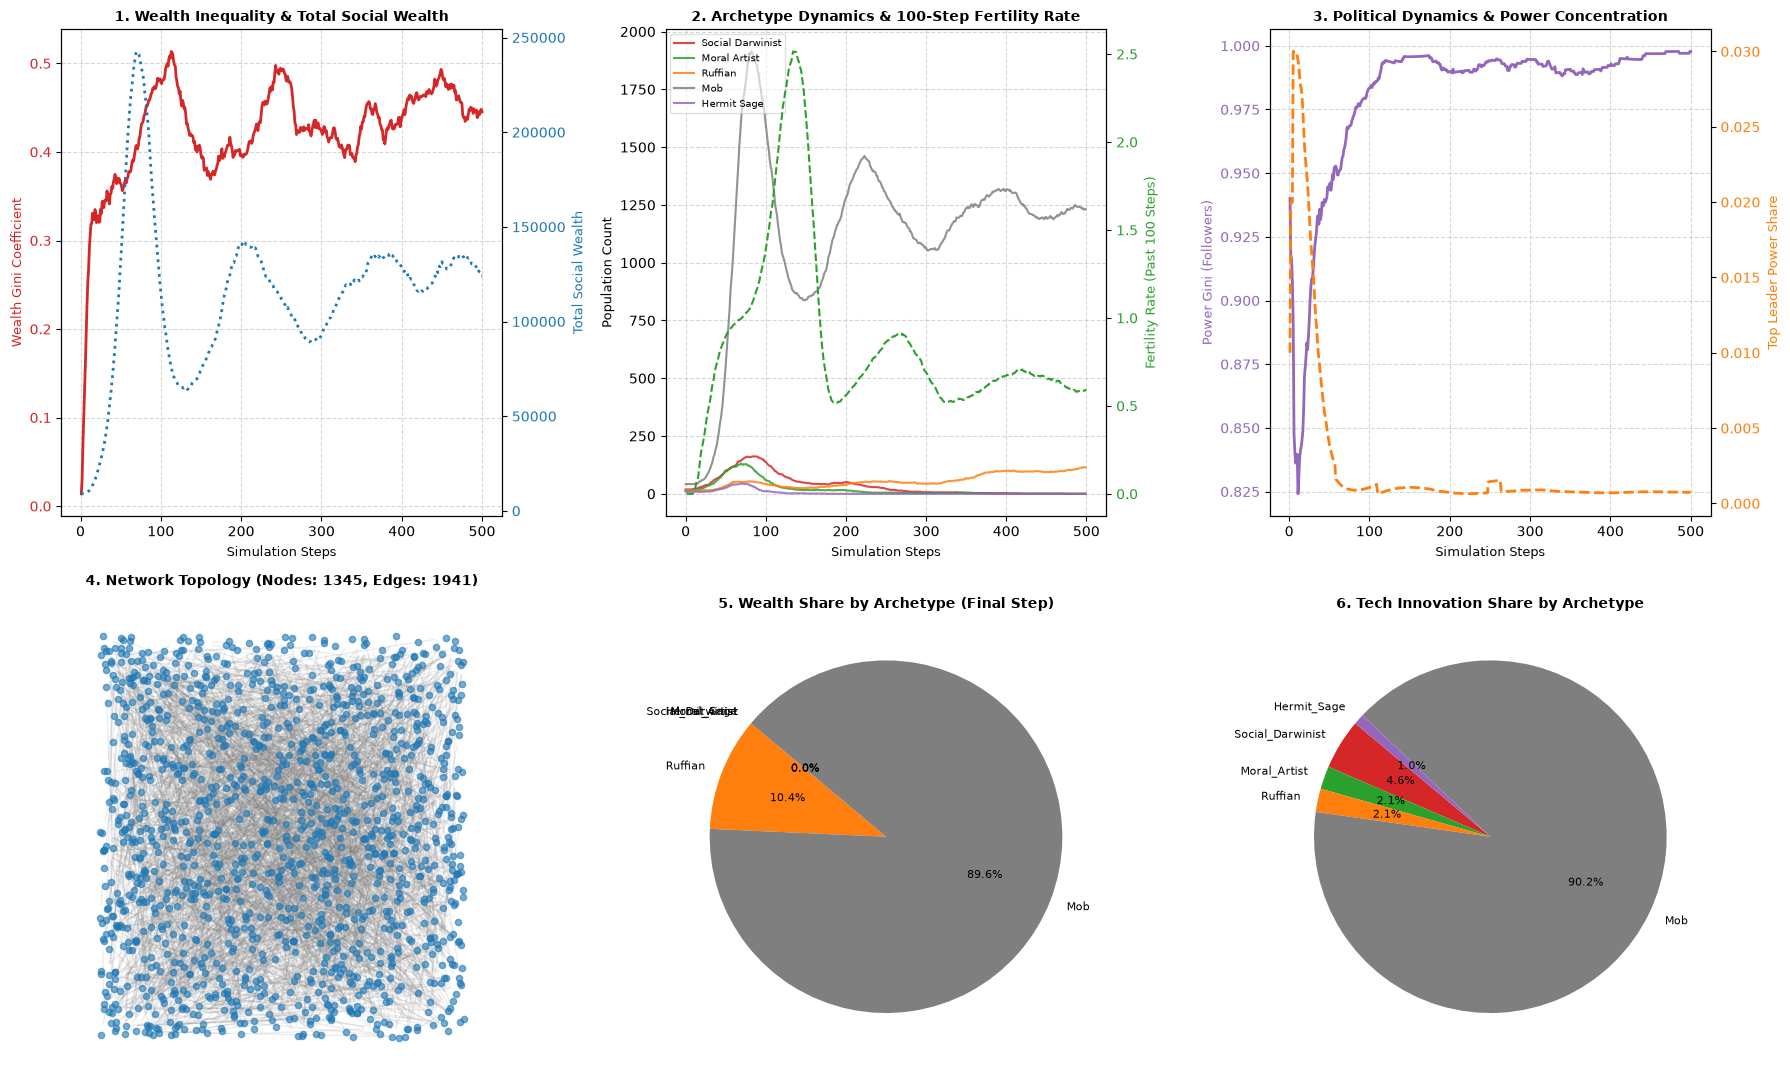

✅ Cell 9: Dashboard visualization generated successfully without font issues!


In [9]:
# Cell 9: 计算社会学全景数据仪表盘 (Pure English Matplotlib Dashboard - No Font Errors)
# ==============================================================================

import matplotlib.pyplot as plt
import networkx as nx

print("✨ Generating Computational Social Science Dashboard (Pure English Mode)...")

# 1. 创建 2x3 布局画布
fig, axs = plt.subplots(2, 3, figsize=(18, 11))

# 设置标准英文字体，彻底避免中文字体缺失导致的方框乱码
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
steps_x = list(range(1, TOTAL_STEPS + 1))

# 获取 DataCollector 数据
data = model.datacollector.get_model_vars_dataframe() if hasattr(model, 'datacollector') else None

# ------------------------------------------------------------------------------
# Chart 1: Wealth Gini & Total Social Wealth Evolution
# ------------------------------------------------------------------------------
ax1 = axs[0, 0]
gini_col = next((c for c in ['Gini_Wealth', 'Wealth_Gini'] if data is not None and c in data.columns), None)
total_w_col = next((c for c in ['Total_Wealth', 'Social_Wealth'] if data is not None and c in data.columns), None)

gini_series = data[gini_col] if gini_col else history_power_gini
total_wealth_series = data[total_w_col] if total_w_col else [0] * TOTAL_STEPS

color = '#d62728'
ax1.set_xlabel('Simulation Steps', fontsize=9)
ax1.set_ylabel('Wealth Gini Coefficient', color=color, fontsize=9)
ax1.plot(steps_x, gini_series, color=color, linewidth=2, label='Wealth Gini')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_sub = ax1.twinx()
color = '#1f77b4'
ax1_sub.set_ylabel('Total Social Wealth', color=color, fontsize=9)
ax1_sub.plot(steps_x, total_wealth_series, color=color, linestyle=':', linewidth=2, label='Total Wealth')
ax1_sub.tick_params(axis='y', labelcolor=color)
ax1.set_title("1. Wealth Inequality & Total Social Wealth", fontsize=10, fontweight='bold')

# ------------------------------------------------------------------------------
# Chart 2: Archetype Population Dynamics & 100-Step Fertility Rate
# ------------------------------------------------------------------------------
ax2 = axs[0, 1]
archetype_colors = {
    'Social_Darwinist_Count': ('#d62728', 'Social Darwinist'),
    'Moral_Artist_Count': ('#2ca02c', 'Moral Artist'),
    'Ruffian_Count': ('#ff7f0e', 'Ruffian'),
    'Mob_Count': ('#7f7f7f', 'Mob'),
    'Hermit_Sage_Count': ('#9467bd', 'Hermit Sage')
}

if data is not None:
    for col, (col_color, label_name) in archetype_colors.items():
        if col in data.columns:
            ax2.plot(data.index, data[col], label=label_name, color=col_color, alpha=0.85)

ax2.set_xlabel('Simulation Steps', fontsize=9)
ax2.set_ylabel('Population Count', fontsize=9)
ax2.set_title("2. Archetype Dynamics & 100-Step Fertility Rate", fontsize=10, fontweight='bold')
ax2.legend(loc='upper left', fontsize=7, framealpha=0.6)
ax2.grid(True, linestyle='--', alpha=0.5)

ax2_sub = ax2.twinx()
color = '#2ca02c'
ax2_sub.set_ylabel('Fertility Rate (Past 100 Steps)', color=color, fontsize=9)
ax2_sub.plot(steps_x, history_recent_fertility_rate, color=color, linestyle='--', linewidth=1.5, label='Fertility Rate')
ax2_sub.tick_params(axis='y', labelcolor=color)

# ------------------------------------------------------------------------------
# Chart 3: Political Structure & Power Concentration
# ------------------------------------------------------------------------------
ax3 = axs[0, 2]
color = '#9467bd'
ax3.set_xlabel('Simulation Steps', fontsize=9)
ax3.set_ylabel('Power Gini (Followers)', color=color, fontsize=9)
ax3.plot(steps_x, history_power_gini, color=color, linewidth=2, label='Power Gini')
ax3.tick_params(axis='y', labelcolor=color)
ax3.grid(True, linestyle='--', alpha=0.5)

ax3_sub = ax3.twinx()
color = '#ff7f0e'
ax3_sub.set_ylabel('Top Leader Power Share', color=color, fontsize=9)
ax3_sub.plot(steps_x, history_top_leader_power, color=color, linestyle='--', linewidth=2, label='Leader Share')
ax3_sub.tick_params(axis='y', labelcolor=color)
ax3.set_title("3. Political Dynamics & Power Concentration", fontsize=10, fontweight='bold')

# ------------------------------------------------------------------------------
# Chart 4: Social Network Topology
# ------------------------------------------------------------------------------
ax4 = axs[1, 0]
social_net_obj = getattr(model, 'social_net', None) or getattr(model, 'network', None)

if social_net_obj and hasattr(social_net_obj, 'graph'):
    G = social_net_obj.graph
    num_nodes = G.number_of_nodes()
    if num_nodes > 0:
        pos_net = nx.spring_layout(G, k=0.15, iterations=15) if num_nodes <= 300 else nx.random_layout(G)
        nx.draw_networkx_nodes(G, pos_net, ax=ax4, node_size=20, node_color='#1f77b4', alpha=0.6)
        nx.draw_networkx_edges(G, pos_net, ax=ax4, alpha=0.15, edge_color='gray')
        ax4.set_title(f"4. Network Topology (Nodes: {num_nodes}, Edges: {G.number_of_edges()})", fontsize=10, fontweight='bold')
    else:
        ax4.text(0.5, 0.5, "No Active Nodes", ha='center', va='center', transform=ax4.transAxes)
else:
    ax4.text(0.5, 0.5, "No Social Network Instance", ha='center', va='center', transform=ax4.transAxes)
ax4.axis('off')

# ------------------------------------------------------------------------------
# Chart 5: Final Wealth Share by Archetype
# ------------------------------------------------------------------------------
ax5 = axs[1, 1]
final_metrics = model.collect_social_metrics() if hasattr(model, 'collect_social_metrics') else {}
wealth_share = final_metrics.get('arch_wealth_share', {}) or final_metrics.get('archetype_wealth_share', {})

if wealth_share and sum(wealth_share.values()) > 0:
    labels = list(wealth_share.keys())
    sizes = [wealth_share[k] for k in labels]
    palette = ['#d62728', '#2ca02c', '#ff7f0e', '#7f7f7f', '#9467bd', '#17becf', '#bcbd22']
    colors = palette[:len(labels)]
    ax5.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax5.set_title("5. Wealth Share by Archetype (Final Step)", fontsize=10, fontweight='bold')
else:
    ax5.text(0.5, 0.5, "No Wealth Data Available", ha='center', va='center', transform=ax5.transAxes)

# ------------------------------------------------------------------------------
# Chart 6: Scientific Tech Contribution Share by Archetype
# ------------------------------------------------------------------------------
ax6 = axs[1, 2]
tech_share = final_metrics.get('tech_share', {}) or final_metrics.get('archetype_tech_share', {})

if tech_share and sum(tech_share.values()) > 0:
    labels = list(tech_share.keys())
    sizes = [tech_share[k] for k in labels]
    palette = ['#d62728', '#2ca02c', '#ff7f0e', '#7f7f7f', '#9467bd', '#17becf', '#bcbd22']
    colors = palette[:len(labels)]
    ax6.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=140, textprops={'fontsize': 8})
    ax6.set_title("6. Tech Innovation Share by Archetype", fontsize=10, fontweight='bold')
else:
    ax6.text(0.5, 0.5, "No Tech Contribution Data Yet", ha='center', va='center', transform=ax6.transAxes)

plt.tight_layout()
plt.show()

print("✅ Cell 9: Dashboard visualization generated successfully without font issues!")